# Os dados do satélite Planck confirmam este modelo do universo primordial?

**Autor:** Fernando de Alvarenga Franco · Mestrado em Física, UNIFEI
**Baseado no artigo:** M. E. S. Antunes, M. Benetti, E. Bittencourt e F. A. Franco, *Constraints on polynomial inflation under power-law perturbations*, Physics of the Dark Universe **48**, 101867 (2025) — [doi:10.1016/j.dark.2025.101867](https://doi.org/10.1016/j.dark.2025.101867)

---

**Em uma frase:** pego dezenas de milhares de amostras públicas da missão espacial Planck, transformo essa nuvem de pontos em regiões de confiança com estatística ponderada e estimativa de densidade, e uso isso para decidir quais versões de um modelo físico são compatíveis com as observações.

| Etapa | O que foi feito | Ferramentas |
|---|---|---|
| Dados | leitura das cadeias de Monte Carlo do Planck 2018, seleção de colunas pelo nome, remoção de *burn-in* | pandas, NumPy |
| Exploração | estatísticas ponderadas, tamanho efetivo da amostra, conferência com os valores oficiais | pandas, NumPy |
| Estatística | estimativa de densidade por kernel (KDE) ponderada com correção de borda, regiões de 68% e 95% | SciPy |
| Modelo | previsões calculadas numericamente (raízes + integração) e conferidas com as fórmulas analíticas do artigo | SciPy |
| Decisão | "nota de compatibilidade" de cada modelo e faixa permitida do parâmetro livre γ | pandas |
| Comunicação | gráficos de comparação modelo × dados | Matplotlib |

## 1. O problema, em um minuto

Logo após o Big Bang, o universo teria passado por uma expansão aceleradíssima chamada **inflação cósmica**. Ela teria sido causada por um campo (o *inflaton*), cujo comportamento é descrito por uma função chamada **potencial**, $V(\phi)$. Cada formato de potencial é um modelo diferente.

Cada modelo deixa uma "impressão digital" na radiação cósmica de fundo, que o satélite Planck mediu. Essa impressão é resumida por dois números:

- **$n_s$ (índice espectral):** diz se as flutuações do universo primordial eram um pouco mais fortes em escalas grandes ou pequenas.
- **$r$ (razão tensor-escalar):** mede quanta onda gravitacional primordial a inflação produziu. Até hoje só temos um **limite superior** para ele.

A pergunta da análise é, então, um problema clássico de dados: **dadas as medições, quais modelos (e com quais parâmetros) continuam plausíveis?**

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# acha a raiz do projeto (a pasta que contém src/), rodando de onde for
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

from estatistica import DensidadeNsR, resumo, tamanho_efetivo, quantil_ponderado, classificar
from modelos import previsao, monomial_analitico, binomial_primeira_ordem
from graficos import aplicar_estilo, contornos, CORES_CONJUNTOS, TINTA, TINTA_SUAVE, ROTULO_NS, ROTULO_R, CMAP_GAMMA, CINZA_DADOS

aplicar_estilo()
pd.set_option("display.float_format", "{:.4f}".format)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

## 2. Os dados

A colaboração Planck publica suas **cadeias de Monte Carlo (MCMC)**: arquivos em que cada linha é uma combinação de parâmetros cosmológicos compatível com as observações, acompanhada de um **peso** (quantas vezes aquela linha "conta"). Quanto mais peso uma região acumula, mais provável ela é.

Uso três combinações de dados do modelo ΛCDM + $r$ (Planck 2018, pacote `COM_CosmoParams_fullGrid_R3.01`):

| Nome | O que inclui |
|---|---|
| **Planck** | temperatura e polarização da radiação cósmica de fundo + lenteamento gravitacional |
| **Planck + BK15** | acrescenta os telescópios BICEP2/Keck Array, que medem $r$ com muito mais precisão |
| **Planck + BK15 + BAO** | acrescenta oscilações acústicas de bárions (medidas com galáxias) |

O pacote original tem 11 GB. O script `scripts/preparar_dados.py` lê os arquivos brutos, encontra as colunas pelo nome (no arquivo `.paramnames`), descarta o *burn-in* quando necessário e salva só peso, $n_s$ e $r$ num arquivo compacto.

In [2]:
dados = pd.read_csv(RAIZ / "dados" / "planck_ns_r.csv.gz")
dados.head()

,conjunto,cadeia,peso,ns,r
0,Planck,1,2.0000,0.9674,0.0017
1,Planck,1,3.0000,0.9677,0.0047
2,Planck,1,1.0000,0.9671,0.0008
3,Planck,1,5.0000,0.9670,0.0017
4,Planck,1,1.0000,0.9619,0.0048


In [3]:
visao_geral = dados.groupby("conjunto", sort=False).agg(
    linhas=("peso", "size"),
    cadeias=("cadeia", "nunique"),
    peso_total=("peso", "sum"),
)
visao_geral["amostras_efetivas"] = dados.groupby("conjunto", sort=False)["peso"].apply(tamanho_efetivo).round()
visao_geral.style.format("{:,.0f}")

,linhas,cadeias,peso_total,amostras_efetivas
conjunto,,,,
Planck,"36,546",4,"89,497","21,605"
Planck + BK15,"97,943",4,"230,949","60,340"
Planck + BK15 + BAO,"22,956",4,806,"15,880"


**Amostras efetivas** é uma medida de quantas amostras independentes e de mesmo peso a cadeia "vale". Ela é menor que o número de linhas porque as linhas têm pesos diferentes. É ela que diz se temos dados suficientes para estimar regiões de confiança com segurança.

## 3. Exploração e conferência com os resultados oficiais

Antes de usar os dados, confiro se reproduzo os números oficiais que o próprio Planck publica junto com as cadeias (arquivos `.margestats`). Como cada linha tem um peso, média, desvio e quantis precisam ser **ponderados**.

In [4]:
colunas = ["ns", "r"]
tabelas = {nome: resumo(grupo, colunas) for nome, grupo in dados.groupby("conjunto", sort=False)}
pd.concat(tabelas, names=["conjunto"])

média  desvio   2,5%  97,5%
conjunto            parâmetro                             
Planck              ns        0.9659  0.0041 0.9579 0.9741
                    r         0.0406  0.0344 0.0012 0.1264
Planck + BK15       ns        0.9651  0.0041 0.9571 0.9730
                    r         0.0270  0.0184 0.0015 0.0696
Planck + BK15 + BAO ns        0.9668  0.0037 0.9596 0.9741
                    r         0.0278  0.0188 0.0016 0.0715

In [5]:
# Valores oficiais: arquivos .margestats que o Planck distribui junto com as cadeias (pasta dist/)
oficial = pd.DataFrame({
    "Planck":              {"n_s média": 0.965936, "n_s desvio": 0.004146, "r limite 95%": 0.10779},
    "Planck + BK15":       {"n_s média": 0.965061, "n_s desvio": 0.004062, "r limite 95%": 0.06135},
    "Planck + BK15 + BAO": {"n_s média": 0.966776, "n_s desvio": 0.003666, "r limite 95%": 0.06288},
}).T

meu = pd.DataFrame({
    nome: {"n_s média": tabelas[nome].loc["ns", "média"],
           "n_s desvio": tabelas[nome].loc["ns", "desvio"],
           "r limite 95%": quantil_ponderado(g["r"], g["peso"], 0.95)}
    for nome, g in dados.groupby("conjunto", sort=False)
}).T

conferencia = pd.concat({"meu cálculo": meu, "Planck (oficial)": oficial}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
conferencia

n_s desvio                    n_s média                   \
                    meu cálculo Planck (oficial) meu cálculo Planck (oficial)   
Planck                   0.0041           0.0041      0.9659           0.9659   
Planck + BK15            0.0041           0.0041      0.9651           0.9651   
Planck + BK15 + BAO      0.0037           0.0037      0.9668           0.9668   

                    r limite 95%                   
                     meu cálculo Planck (oficial)  
Planck                    0.1078           0.1078  
Planck + BK15             0.0614           0.0614  
Planck + BK15 + BAO       0.0629           0.0629

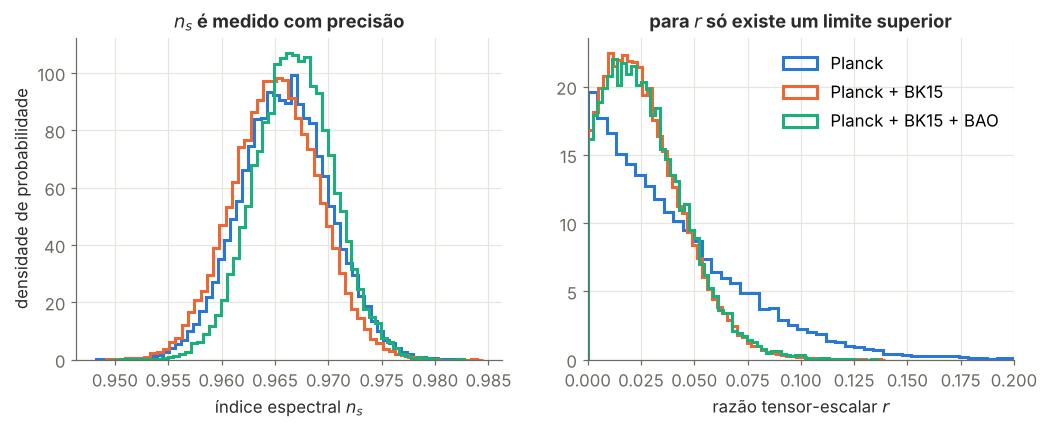

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
for nome, g in dados.groupby("conjunto", sort=False):
    cor = CORES_CONJUNTOS[nome]
    eixos[0].hist(g["ns"], bins=60, weights=g["peso"], density=True, histtype="step", color=cor, lw=2, label=nome)
    eixos[1].hist(g["r"], bins=60, weights=g["peso"], density=True, histtype="step", color=cor, lw=2, label=nome)
eixos[0].set(xlabel=ROTULO_NS, ylabel="densidade de probabilidade", title="$n_s$ é medido com precisão")
eixos[1].set(xlabel=ROTULO_R, title="para $r$ só existe um limite superior")
eixos[1].set_xlim(0, 0.2)
eixos[1].legend()
fig.savefig(FIGURAS / "distribuicoes.png")
plt.show()

**Leitura:** as três combinações concordam sobre $n_s$, mas os dados do BICEP/Keck (laranja e verde) empurram $r$ para valores bem menores. É esse limite em $r$ que mais vai separar os modelos.

## 4. Da nuvem de pontos para regiões de confiança

Para comparar um modelo com os dados preciso responder: *"a previsão deste modelo cai numa região provável ou improvável?"* Para isso transformo a nuvem de amostras numa superfície de probabilidade suave com **estimativa de densidade por kernel (KDE)**, que coloca uma pequena gaussiana em cada ponto e soma tudo.

Dois cuidados que fazem diferença:

1. **Pesos.** A KDE é construída reamostrando os pontos proporcionalmente ao peso. Ignorar os pesos daria importância demais a regiões pouco prováveis.
2. **Borda em $r = 0$.** Como $r$ não pode ser negativo, uma KDE ingênua "vaza" probabilidade para $r < 0$ e subestima a densidade justamente onde ficam os modelos com $r$ pequeno. Corrijo isso com o **método da reflexão**: espelho os pontos em $r \to -r$ e devolvo essa probabilidade para o lado físico.

A região de **68%** (ou **95%**) é a menor região que contém 68% (ou 95%) da probabilidade. Calibro esses níveis com as próprias amostras, sem precisar integrar numa grade.

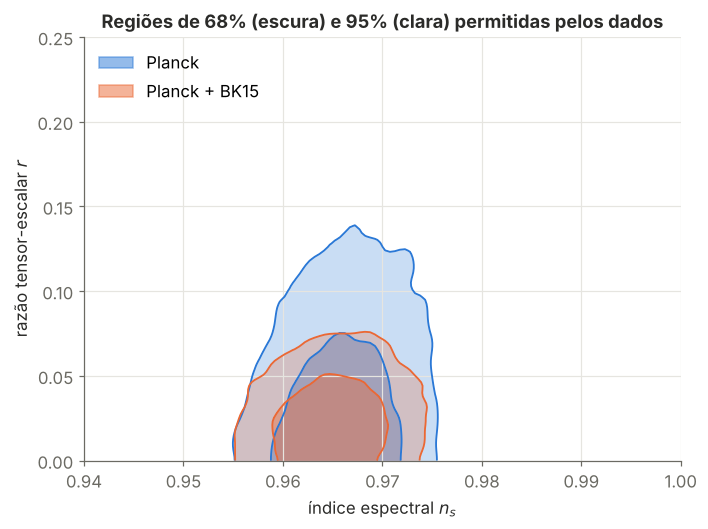

In [7]:
densidades = {
    nome: DensidadeNsR(g["ns"], g["r"], g["peso"])
    for nome, g in dados.groupby("conjunto", sort=False)
}

fig, ax = plt.subplots(figsize=(7, 5))
for nome in ["Planck", "Planck + BK15"]:
    contornos(ax, densidades[nome], CORES_CONJUNTOS[nome], rotulo=nome)
ax.set_title("Regiões de 68% (escura) e 95% (clara) permitidas pelos dados")
ax.legend(loc="upper left")
fig.savefig(FIGURAS / "regioes_de_confianca.png")
plt.show()

## 5. O que o modelo prevê

O modelo mais simples do artigo é o **potencial monomial**, $V(\phi) \propto \phi^n$. Para cada expoente $n$, a teoria de rolamento lento dá $n_s$ e $r$ em função de $N_*$, o número de *e-folds* (quanto o universo cresceu) entre o momento observado e o fim da inflação. Como $N_*$ não é conhecido com exatidão, uso a faixa padrão de **50 a 60**.

Em vez de copiar fórmulas prontas, escrevi um código que resolve o problema **numericamente** (encontra o fim da inflação com um método de raízes e integra o número de e-folds). Assim o mesmo código serve também para potenciais sem fórmula fechada (seção 7). Primeiro, a conferência com as fórmulas analíticas do artigo:

In [8]:
EXPOENTES = {"n = 1/2": 1 / 2, "n = 2/3": 2 / 3, "n = 1": 1.0, "n = 2": 2.0}

linhas = []
for rotulo, n in EXPOENTES.items():
    for N in (50, 60):
        p = previsao(n, N)
        ns_a, r_a = monomial_analitico(n, N)
        linhas.append({"modelo": rotulo, "N*": N, "n_s (numérico)": p["ns"], "n_s (fórmula)": ns_a,
                       "r (numérico)": p["r"], "r (fórmula)": r_a})
previsoes_monomial = pd.DataFrame(linhas)
previsoes_monomial.style.format(precision=6).hide(axis="index")

modelo,N*,n_s (numérico),n_s (fórmula),r (numérico),r (fórmula)
n = 1/2,50,0.975062,0.975062,0.039900,0.039900
n = 1/2,60,0.979210,0.979210,0.033264,0.033264
n = 2/3,50,0.973422,0.973422,0.053156,0.053156
n = 2/3,60,0.977839,0.977839,0.044321,0.044321
n = 1,50,0.970149,0.970149,0.079602,0.079602
n = 1,60,0.975104,0.975104,0.066390,0.066390
n = 2,50,0.960396,0.960396,0.158416,0.158416
n = 2,60,0.966942,0.966942,0.132231,0.132231


O cálculo numérico e as fórmulas concordam em todas as casas decimais (há também testes automáticos para isso em `tests/`). Agora coloco as previsões sobre os dados. Cada segmento vai de $N_* = 50$ (círculo vazio) a $N_* = 60$ (círculo cheio):

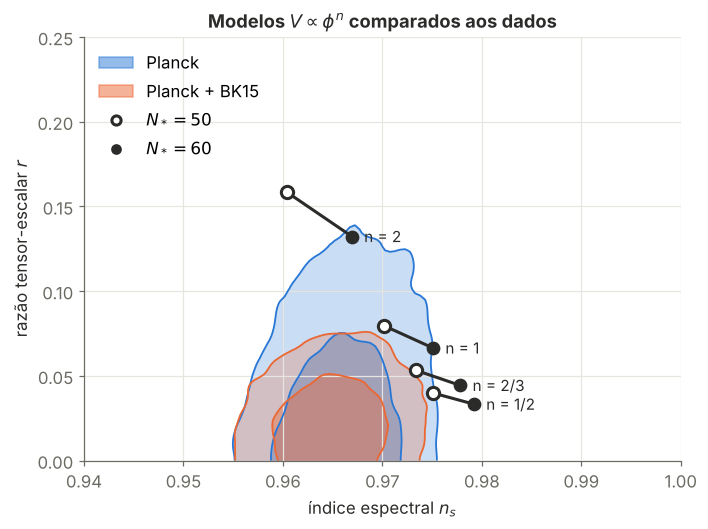

In [9]:
def desenhar_monomiais(ax):
    for rotulo, n in EXPOENTES.items():
        p50, p60 = previsao(n, 50), previsao(n, 60)
        ax.plot([p50["ns"], p60["ns"]], [p50["r"], p60["r"]], color=TINTA, lw=2, zorder=5)
        ax.plot(p50["ns"], p50["r"], "o", ms=8, mfc="white", mec=TINTA, mew=2, zorder=6)
        ax.plot(p60["ns"], p60["r"], "o", ms=8, color=TINTA, zorder=6)
        ax.annotate(rotulo, (p60["ns"], p60["r"]), xytext=(8, 0), textcoords="offset points",
                    va="center", color=TINTA, fontsize=10, zorder=7)

fig, ax = plt.subplots(figsize=(7, 5))
for nome in ["Planck", "Planck + BK15"]:
    contornos(ax, densidades[nome], CORES_CONJUNTOS[nome], rotulo=nome)
desenhar_monomiais(ax)
ax.plot([], [], "o", mfc="white", mec=TINTA, mew=2, label="$N_* = 50$")
ax.plot([], [], "o", color=TINTA, label="$N_* = 60$")
ax.set_title(r"Modelos $V \propto \phi^n$ comparados aos dados")
ax.legend(loc="upper left")
fig.savefig(FIGURAS / "monomial_vs_planck.png")
plt.show()

## 6. Quão compatível é cada modelo? Uma nota objetiva

O gráfico dá uma impressão visual. Para decidir com um critério objetivo, calculo para cada previsão a **menor região de credibilidade que a contém**:

- até **68%**: o modelo está no "miolo" do que os dados permitem;
- entre **68% e 95%**: ainda aceitável;
- acima de **95%**: o modelo está **em tensão** com os dados (a convenção usual para considerá-lo descartado).

In [10]:
linhas = []
for rotulo, n in EXPOENTES.items():
    for N in (50, 55, 60):
        p = previsao(n, N)
        linha = {"modelo": rotulo, "N*": N}
        for nome, dens in densidades.items():
            linha[nome] = dens.credibilidade(p["ns"], p["r"])
        linhas.append(linha)
notas = pd.DataFrame(linhas).set_index(["modelo", "N*"])

def colorir(valor):
    if valor <= 68: return "background-color: #d4edda"
    if valor <= 95: return "background-color: #fff3cd"
    return "background-color: #f8d7da"

notas.style.format("{:.0f}%").map(colorir)

In [11]:
# Resumo em texto: quantas combinações modelo × N* sobrevivem a cada conjunto de dados
for nome in densidades:
    ok = (notas[nome] <= 95).sum()
    print(f"{nome:22s}: {ok} de {len(notas)} combinações dentro da região de 95%")

Planck                : 5 de 12 combinações dentro da região de 95%
Planck + BK15         : 0 de 12 combinações dentro da região de 95%
Planck + BK15 + BAO   : 1 de 12 combinações dentro da região de 95%


**Leitura:** só com o Planck, 5 das 12 combinações passam: os potenciais côncavos ($n = 1/2$ e $2/3$) e o linear com $N_*$ perto de 50, e o quadrático ($n = 2$) apenas com $N_* = 60$. Quando entram os dados do BICEP/Keck, que limitam muito $r$, **nenhuma** das 12 combinações fica dentro da região de 95% (com BAO, sobra só $n = 2/3$ com $N_* = 50$, exatamente na fronteira). É a mesma conclusão do artigo: o limite em $r$ descarta os potenciais monomiais.

## 7. Indo além: o potencial binomial

O artigo propõe "corrigir" o monomial com um segundo termo, controlado por um parâmetro livre $\gamma$:

$$V(\phi) \propto \phi^n\,(1 + \gamma\,\phi^{m-n}), \qquad m = n+1 \ \text{ou}\ m = n+2.$$

A pergunta passa a ser: **que valores de $\gamma$ os dados permitem?**

No artigo, as previsões foram obtidas com fórmulas aproximadas (válidas em primeira ordem em $\gamma$). Aqui uso o cálculo numérico exato e comparo os dois, o que mostra até onde a aproximação é confiável:

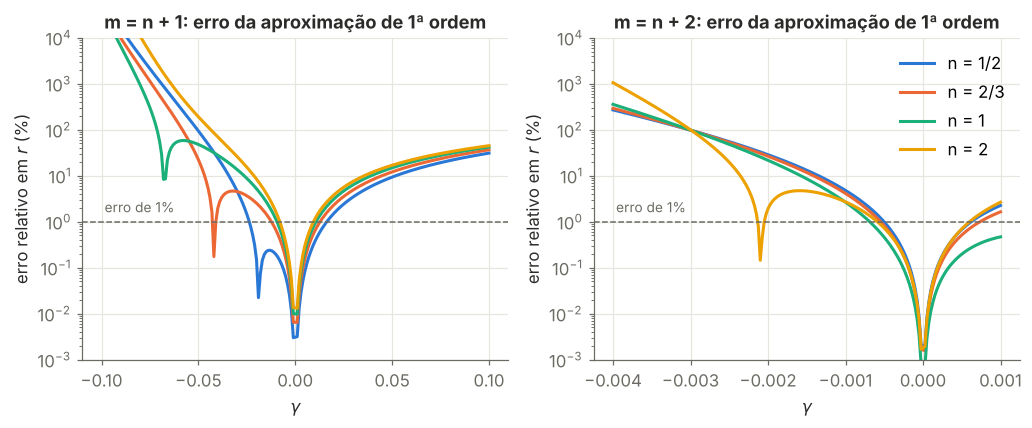

In [12]:
CASOS = {"m = n + 1": (1, "m=n+1", np.linspace(-0.1, 0.1, 201)),
         "m = n + 2": (2, "m=n+2", np.linspace(-4e-3, 1e-3, 201))}

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (titulo, (dm, caso, gammas)) in zip(eixos, CASOS.items()):
    for rotulo, n in EXPOENTES.items():
        exato = np.array([previsao(n, 55, g, m=n + dm)["r"] for g in gammas])
        aprox = np.array([binomial_primeira_ordem(n, 55, g, caso)[1] for g in gammas])
        sem_zero = gammas != 0  # em γ = 0 as duas coincidem exatamente
        erro = 100 * np.abs(aprox - exato) / exato
        ax.plot(gammas[sem_zero], erro[sem_zero], label=rotulo)
    ax.axhline(1, color=TINTA_SUAVE, lw=1, ls="--")
    ax.annotate("erro de 1%", (gammas.min(), 1), xytext=(2, 4), textcoords="offset points", va="bottom", color=TINTA_SUAVE, fontsize=9)
    ax.set(title=f"{titulo}: erro da aproximação de 1ª ordem", xlabel=r"$\gamma$",
           ylabel="erro relativo em $r$ (%)", yscale="log", ylim=(1e-3, 1e4))
eixos[1].legend()
fig.savefig(FIGURAS / "validacao_aproximacao.png")
plt.show()

**Leitura:** perto de $\gamma = 0$ a aproximação é excelente (erro muito abaixo de 1%), mas ela piora rápido quando $|\gamma|$ cresce. Para $\gamma$ negativo e grande o potencial chega a "virar para baixo" e a fórmula de primeira ordem deixa de valer. Por isso, daqui em diante uso sempre o cálculo exato.

Agora, o caminho que a previsão percorre no plano $(n_s, r)$ quando $\gamma$ varia, sobre os dados do Planck + BK15 (violeta = $\gamma$ negativo, cinza = $\gamma$ perto de zero, laranja = $\gamma$ positivo; o rótulo no fim de cada curva indica o $N_*$):

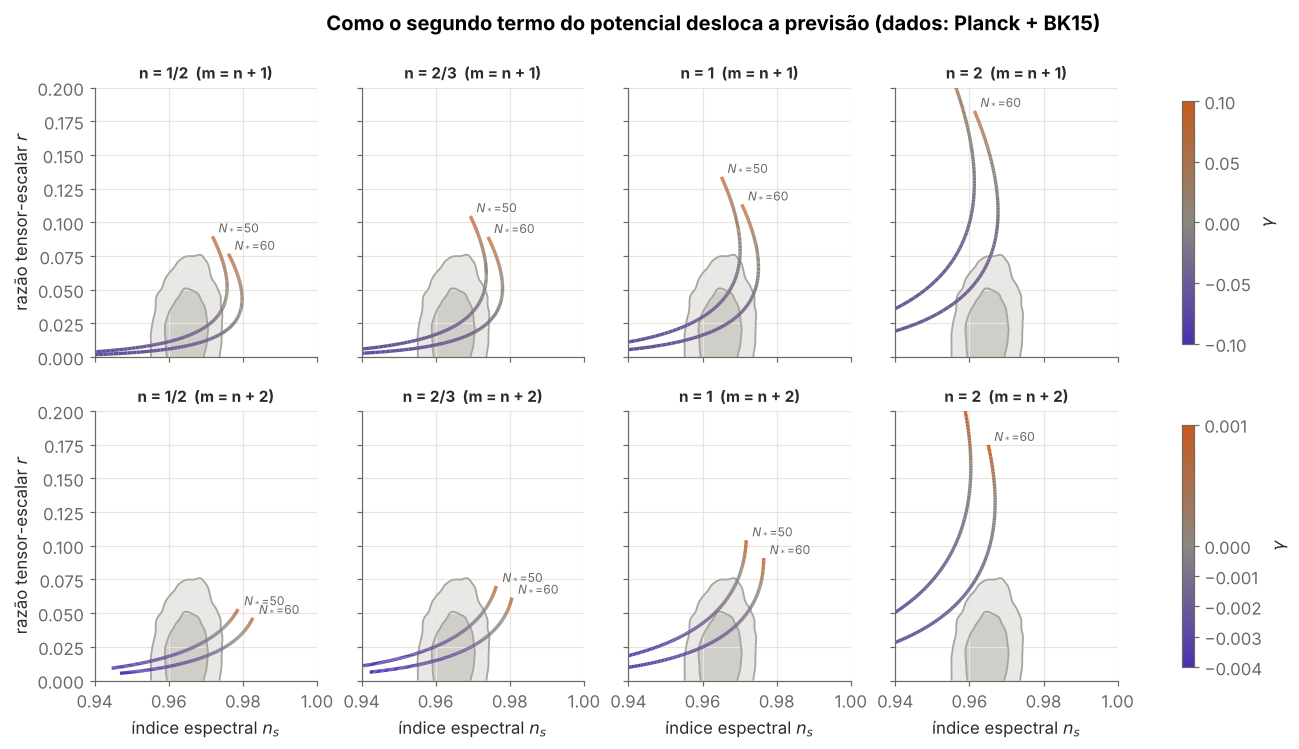

In [13]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.collections import LineCollection

def varrer(n, dm, gammas, N):
    return pd.DataFrame([previsao(n, N, g, m=n + dm) for g in gammas])

varreduras = {
    (caso, rotulo, N): varrer(n, dm, gammas, N)
    for caso, (dm, _, gammas) in CASOS.items()
    for rotulo, n in EXPOENTES.items()
    for N in (50, 60)
}

dens = densidades["Planck + BK15"]
fig, eixos = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
for linha, (caso, (dm, _, gammas)) in zip(eixos, CASOS.items()):
    norma = TwoSlopeNorm(vmin=gammas.min(), vcenter=0, vmax=gammas.max())
    for ax, (rotulo, n) in zip(linha, EXPOENTES.items()):
        contornos(ax, dens, CINZA_DADOS, ns_lim=(0.94, 1.0), r_lim=(0, 0.2))
        for N in (50, 60):
            v = varreduras[(caso, rotulo, N)].dropna()
            pts = v[["ns", "r"]].to_numpy()
            seg = LineCollection(np.stack([pts[:-1], pts[1:]], axis=1), cmap=CMAP_GAMMA, norm=norma,
                                 linewidths=2.2)
            seg.set_array(v["gamma"].to_numpy()[:-1])
            ax.add_collection(seg)
            # rótulo direto no fim da curva (γ máximo) dizendo qual é o N*
            ax.annotate(f"$N_*$={N}", pts[-1], xytext=(4, 2), textcoords="offset points",
                        fontsize=8, color=TINTA_SUAVE, clip_on=True)
        ax.set_title(f"{rotulo}  ({caso})", fontsize=10)
        ax.label_outer()
    fig.colorbar(seg, ax=linha, label=r"$\gamma$", shrink=0.9)
fig.suptitle("Como o segundo termo do potencial desloca a previsão (dados: Planck + BK15)", fontweight="bold")
fig.savefig(FIGURAS / "binomial_trajetorias.png")
plt.show()

### Resultado: a faixa de $\gamma$ permitida pelos dados

Para cada caso, expoente $n$ e $N_*$, procuro os valores de $\gamma$ cuja previsão fica dentro da região de 95% do Planck + BK15:

In [14]:
def faixa_permitida(v, dens, limite=95):
    v = v.dropna()
    ok = dens.credibilidade(v["ns"].to_numpy(), v["r"].to_numpy()) <= limite
    if not ok.any():
        return "nenhum valor"
    g = v["gamma"].to_numpy()[ok]
    fmt = (lambda x: f"{x:+.3f}") if abs(g).max() > 0.01 else (lambda x: f"{x:+.1e}")
    continuo = np.all(np.diff(np.nonzero(ok)[0]) == 1)  # a faixa não tem "buracos"?
    return f"{fmt(g.min())} a {fmt(g.max())}" + ("" if continuo else " (com lacunas)")

restricoes = pd.DataFrame([
    {"caso": caso, "modelo": rotulo, "N*": N, "γ permitido (95%)": faixa_permitida(v, dens)}
    for (caso, rotulo, N), v in varreduras.items()
]).pivot_table(index=["caso", "modelo"], columns="N*", values="γ permitido (95%)", aggfunc="first")
restricoes.columns = [f"N* = {c}" for c in restricoes.columns]
restricoes = restricoes.reindex([(c, m) for c in CASOS for m in EXPOENTES])
restricoes

N* = 50              N* = 60
caso      modelo                                           
m = n + 1 n = 1/2      -0.046 a -0.007      -0.050 a -0.024
          n = 2/3      -0.047 a -0.004      -0.050 a -0.022
          n = 1        -0.045 a -0.008      -0.049 a -0.018
          n = 2           nenhum valor      -0.040 a -0.029
m = n + 2 n = 1/2  -2.9e-03 a -2.2e-04  -3.2e-03 a -9.0e-04
          n = 2/3  -2.6e-03 a -1.0e-04  -2.9e-03 a -7.0e-04
          n = 1    -2.1e-03 a -2.5e-04  -2.4e-03 a -5.7e-04
          n = 2           nenhum valor         nenhum valor

**Por que o cálculo exato fazia diferença:** a faixa permitida para $m = n+1$ ($\gamma$ entre cerca de $-0{,}05$ e $-0{,}005$) cai justamente onde, no gráfico de validação acima, a aproximação de primeira ordem erra mais de 1% (chegando a dezenas de por cento). Sem o cálculo numérico, essa conclusão sairia distorcida.

## 8. Conclusões

- **Dados:** usei as cadeias públicas do Planck 2018 em três combinações e, antes de qualquer conclusão, reproduzi os números oficiais do próprio Planck (médias, desvios e limites de 95%).
- **Monomial:** com o Planck sozinho, 5 de 12 combinações de modelo e $N_*$ são compatíveis; com o BICEP/Keck, nenhuma. Os potenciais $V \propto \phi^n$ não sobrevivem ao limite atual em $r$.
- **Binomial:** o segundo termo resgata os modelos, mas **só com $\gamma$ negativo**, que achata o potencial e diminui $r$. Com $m = n+1$ a faixa permitida fica em torno de $-0{,}05 < \gamma < -0{,}005$; com $m = n+2$, em torno de $-3 \times 10^{-3} < \gamma < -10^{-4}$. O quadrático com $m = n+2$ não é salvo por nenhum valor de $\gamma$.
- **Método:** a "nota de compatibilidade" baseada em regiões de credibilidade transforma uma comparação visual num critério objetivo e reproduzível, que funciona como filtro sobre o parâmetro livre do modelo.

**Limitações e próximos passos**

- As previsões usam a aproximação de rolamento lento; um próximo passo seria resolver as perturbações completas (como feito no artigo com o código CAMB modificado, para o parâmetro $\sigma_8$).
- A região de confiança depende da largura de banda da KDE; uma análise de sensibilidade a esse parâmetro deixaria o resultado mais robusto.
- Uma análise completa ajustaria $\gamma$ diretamente aos dados, por exemplo com MCMC, em vez de apenas filtrar uma grade de valores.